# Lung cancer classification — data and model visualizations

Run **Restart Kernel → Run All** from the repository root or this notebook's folder.
All imports, paths, plotting settings and helper functions are initialized in the first code cell.
No model is fitted or tuned. Figures are displayed inline and saved as PNG and SVG in
`results/vis_res`; derived tables and a source manifest are saved there too.

**Requirements:** the repository's `requirements.txt`, plus Jupyter (or VS Code's notebook support).
XGBoost is optional for aggregate charts; install it to obtain fresh predictions from the saved
JSON models and include their ROC/precision–recall curves.

**Interpretation:** YES = 1, NO = 0. The dataset is imbalanced; these charts assess that rather
than assume balance. Random Forest was tuned/refit on all training rows; the saved XGBoost
models were selected from individual CV folds. The holdout comparison describes these saved
artifacts, not a controlled claim that one algorithm is superior. Do not select a winner using
this test set and then report the same test as an untouched final evaluation.


In [1]:
from pathlib import Path
import json
import hashlib
import warnings
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve,
    precision_recall_curve, average_precision_score,
)

try:
    import xgboost as xgb
except ImportError:
    xgb = None

# Set this only if launching outside the repository directory tree.
ROOT_OVERRIDE = None  # e.g. Path(r"D:/Code/Lung_Cancer_Classification_Random-Forest_and_XGBoost")
roots = [Path(ROOT_OVERRIDE)] if ROOT_OVERRIDE else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in roots if (p / 'data/raw/survey_lung_cancer.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Set ROOT_OVERRIDE to the repository root, then rerun this cell.')
OUT = ROOT / 'results/vis_res'
OUT.mkdir(parents=True, exist_ok=True)
RF_DIR = ROOT / 'results/random_forest'
TARGET = 'LUNG_CANCER'
LABELS = ['NO', 'YES']
COLORS = {'NO': '#3B82A0', 'YES': '#D97843'}
METRICS = ['Accuracy', 'Balanced accuracy', 'Precision YES', 'Recall YES', 'Recall NO', 'F1 YES', 'F1 macro', 'ROC-AUC']
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.02)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 220, 'axes.spines.top': False, 'axes.spines.right': False})
SOURCES, FIGURES, NOTES = {}, [], []

def source(path):
    path = Path(path)
    SOURCES[str(path.relative_to(ROOT))] = hashlib.sha256(path.read_bytes()).hexdigest()
    return path

def csv(path, **kwargs):
    return pd.read_csv(source(path), **kwargs)

def js(path):
    return json.loads(source(path).read_text(encoding='utf-8'))

def note(message):
    NOTES.append(message)
    print(message)

def xgb_result(filename):
    # Canonical tracked results take precedence over the legacy script output.
    candidates = [ROOT / 'results/XGBoost' / filename,
                  ROOT / 'src/models/XGBoost/trained_and_tested' / filename]
    found = [p for p in candidates if p.exists()]
    if not found:
        raise FileNotFoundError(f'Missing {filename}; checked {candidates}')
    if len(found) > 1 and found[0].read_bytes() != found[1].read_bytes():
        note(f'Different copies of {filename} exist; using {found[0].relative_to(ROOT)}.')
    return found[0]

def savefig(fig, name):
    fig.tight_layout()
    for ext in ['png', 'svg']:
        fig.savefig(OUT / f'{name}.{ext}', bbox_inches='tight')
    FIGURES.append(name)
    plt.show()
    plt.close(fig)

def table(df, name):
    df.to_csv(OUT / f'{name}.csv', index=False)
    display(df)

def safe_ratio(a, b):
    return a / b if b else 0.0

def metrics_from_cm(cm, auc):
    tn, fp, fn, tp = np.asarray(cm).ravel()
    r0, r1 = safe_ratio(tn, tn + fp), safe_ratio(tp, tp + fn)
    f0, f1 = safe_ratio(2*tn, 2*tn + fp + fn), safe_ratio(2*tp, 2*tp + fp + fn)
    return {'Accuracy': safe_ratio(tn + tp, cm.sum()), 'Balanced accuracy': (r0+r1)/2,
            'Precision YES': safe_ratio(tp, tp+fp), 'Recall YES': r1, 'Recall NO': r0,
            'F1 YES': f1, 'F1 macro': (f0+f1)/2, 'ROC-AUC': float(auc)}

def unique_cm_from_summary(row, y):
    # Exact integer enumeration, not invented per-sample predictions. Require uniqueness.
    n0, n1 = (int((y == label).sum()) for label in [0, 1])
    matches = []
    for tn in range(n0+1):
        for tp in range(n1+1):
            cm = np.array([[tn, n0-tn], [n1-tp, tp]])
            m = metrics_from_cm(cm, row['ROC-AUC'])
            if all(np.isclose(m[a], float(row[b]), atol=1e-8, rtol=0)
                   for a, b in [('Accuracy','Accuracy'), ('Precision YES','Precision'),
                                ('Recall YES','Recall'), ('F1 YES','F1-Score')]):
                matches.append(cm)
    if len(matches) != 1:
        raise ValueError(f'Cannot uniquely recover confusion matrix: {len(matches)} matches. Load saved model predictions instead.')
    return matches[0]

print('Repository:', ROOT)
print('Figure output:', OUT)


Repository: F:\Bach_khoa\HKCQ\HK261\Machine Learning\BTL
Figure output: F:\Bach_khoa\HKCQ\HK261\Machine Learning\BTL\results\vis_res


## 1. Load and audit the data
Missingness is counted before encoding; invalid category codes are checked separately so that
encoding cannot silently disguise them as missing values. Duplicate counts mean extra copies
of a complete row, not necessarily duplicate people (the dataset has no patient identifier).


,Dataset,Rows,Duplicate rows,Missing cells
0,Raw,309,33,0
1,Deduplicated raw,276,0,0
2,Train,220,0,0
3,Test,56,0,0


,Feature,Missing,Invalid nonmissing
0,GENDER,0,0
1,AGE,0,0
2,SMOKING,0,0
3,YELLOW_FINGERS,0,0
4,ANXIETY,0,0
5,PEER_PRESSURE,0,0
6,CHRONIC DISEASE,0,0
7,FATIGUE,0,0
8,ALLERGY,0,0
9,WHEEZING,0,0


Feature-identical rows shared between train and test: 0
Raw duplicate rows removed: 33
Processed rows equal the encoded deduplicated raw rows: True


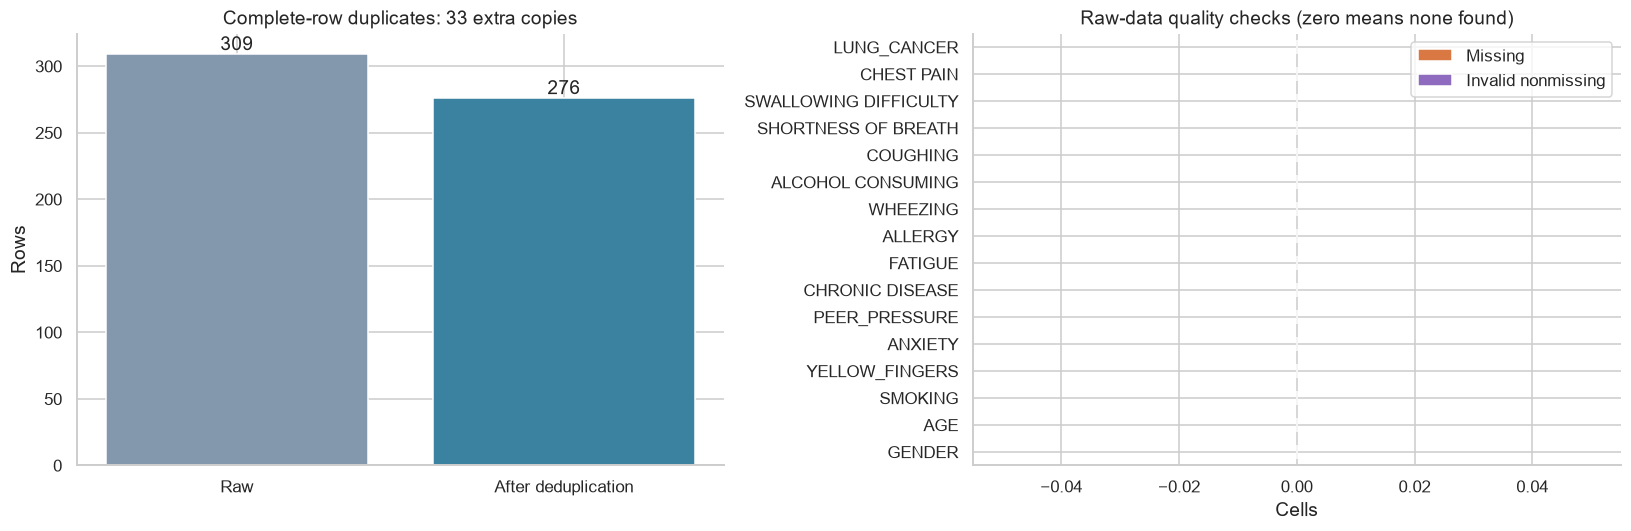

In [2]:
raw = csv(ROOT / 'data/raw/survey_lung_cancer.csv')
raw.columns = raw.columns.str.strip()
train = csv(ROOT / 'data/processed/train.csv')
test = csv(ROOT / 'data/processed/test.csv')
features = [c for c in train.columns if c != TARGET]
symptoms = [c for c in features if c not in ['AGE', 'GENDER']]
X_test, y_test = test[features], test[TARGET].astype(int)
assert set(y_test.unique()) == {0, 1}, 'Both classes are required for this evaluation.'
assert list(train.columns) == list(test.columns), 'Train/test schemas differ.'
clean = raw.drop_duplicates().copy()
encoded = clean.copy()
encoded['GENDER'] = encoded['GENDER'].map({'M': 1, 'F': 0})
encoded[TARGET] = encoded[TARGET].map({'YES': 1, 'NO': 0})
encoded[symptoms] = encoded[symptoms].apply(lambda s: s.map({1: 0, 2: 1}))

quality = pd.DataFrame({
    'Feature': raw.columns,
    'Missing': raw.isna().sum().values,
    'Invalid nonmissing': [int((raw[c].notna() & ~raw[c].isin(
        ['M','F'] if c == 'GENDER' else ['YES','NO'] if c == TARGET else [1,2])).sum())
        if c != 'AGE' else int((raw[c].notna() & (~pd.to_numeric(raw[c], errors='coerce').between(0,120))).sum())
        for c in raw.columns],
})
audit = pd.DataFrame([
    {'Dataset': name, 'Rows': len(df), 'Duplicate rows': int(df.duplicated().sum()),
     'Missing cells': int(df.isna().sum().sum())}
    for name, df in [('Raw',raw), ('Deduplicated raw',clean), ('Train',train), ('Test',test)]]
)
overlap = len(set(map(tuple, train[features].to_numpy())) & set(map(tuple, test[features].to_numpy())))
table(audit, 'data_audit')
table(quality, 'feature_quality')
print('Feature-identical rows shared between train and test:', overlap)
print('Raw duplicate rows removed:', len(raw)-len(clean))
print('Processed rows equal the encoded deduplicated raw rows:',
      set(map(tuple, encoded[train.columns].to_numpy())) == set(map(tuple, pd.concat([train,test]).to_numpy())))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(['Raw', 'After deduplication'], [len(raw), len(clean)], color=['#8398AC','#3B82A0'])
for i, n in enumerate([len(raw),len(clean)]):
    axes[0].text(i, n, str(n), ha='center', va='bottom')
axes[0].set(title=f'Complete-row duplicates: {len(raw)-len(clean)} extra copies', ylabel='Rows')
quality.set_index('Feature')[['Missing','Invalid nonmissing']].plot.barh(ax=axes[1], color=['#D97843','#8E6BBE'])
axes[1].set(title='Raw-data quality checks (zero means none found)', xlabel='Cells', ylabel='')
savefig(fig, '01_data_quality')


### Class balance and split consistency
Stratification preserves the imbalance; it does not make classes equally frequent.
The majority-only accuracy baseline is displayed alongside the class proportions.


,Dataset,NO,YES
0,Raw,39,270
1,Deduplicated,38,238
2,Train,30,190
3,Test,8,48


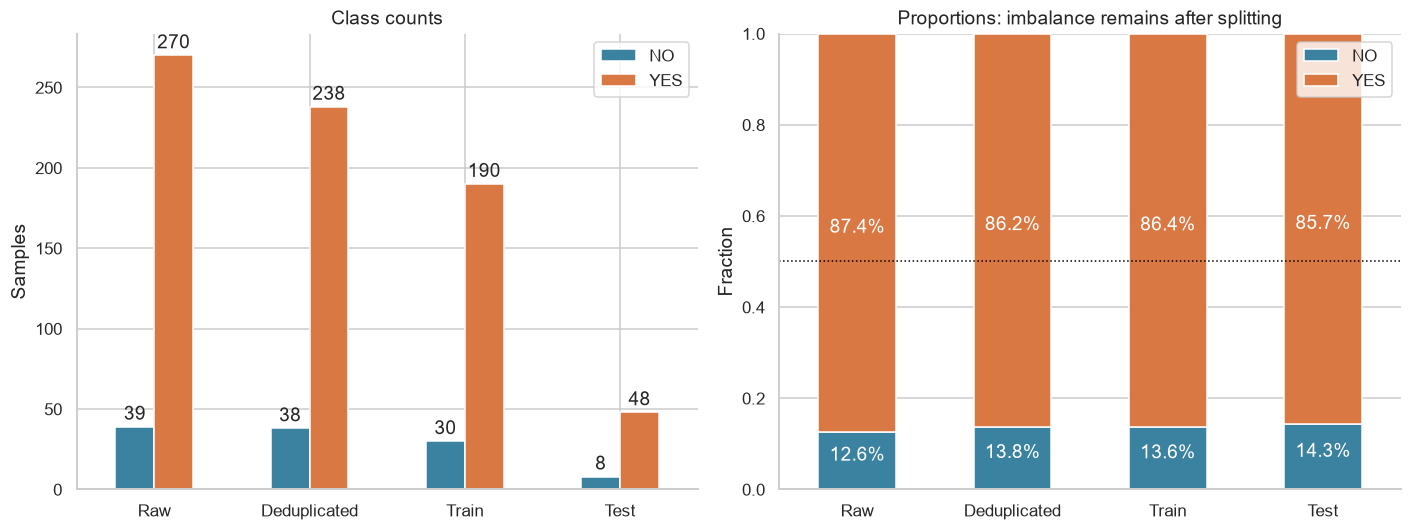

Majority-only test accuracy: 85.71%


In [3]:
distributions = {}
for name, y in [('Raw',raw[TARGET].map({'NO':0,'YES':1})), ('Deduplicated',encoded[TARGET]),
                ('Train',train[TARGET]), ('Test',test[TARGET])]:
    distributions[name] = y.value_counts().reindex([0,1], fill_value=0).to_numpy()
counts = pd.DataFrame(distributions, index=LABELS).T
props = counts.div(counts.sum(axis=1), axis=0)
table(counts.rename_axis('Dataset').reset_index(), 'class_counts')
fig, axes = plt.subplots(1,2,figsize=(13,5))
counts.plot.bar(ax=axes[0], color=[COLORS[x] for x in LABELS], rot=0)
axes[0].set(title='Class counts', ylabel='Samples', xlabel='')
for container in axes[0].containers:
    axes[0].bar_label(container, padding=2)
props.plot.bar(stacked=True, ax=axes[1], color=[COLORS[x] for x in LABELS], rot=0)
for i, name in enumerate(props.index):
    axes[1].text(i, props.loc[name,'NO']/2, f"{props.loc[name,'NO']:.1%}", ha='center', color='white')
    axes[1].text(i, props.loc[name,'NO']+props.loc[name,'YES']/2, f"{props.loc[name,'YES']:.1%}", ha='center', color='white')
axes[1].axhline(.5,color='black',ls=':',lw=1,label='50% reference')
axes[1].set(title='Proportions: imbalance remains after splitting', ylabel='Fraction', xlabel='', ylim=(0,1))
savefig(fig, '02_class_balance')
print(f'Majority-only test accuracy: {props.loc["Test"].max():.2%}')


### Feature distributions and associations
Age plots can identify unusual observations but do not justify deleting plausible ages.
The symptom heatmap uses within-class percentages, avoiding distortion by unequal class sizes.
These are descriptive associations, not causal effects or model feature importance.


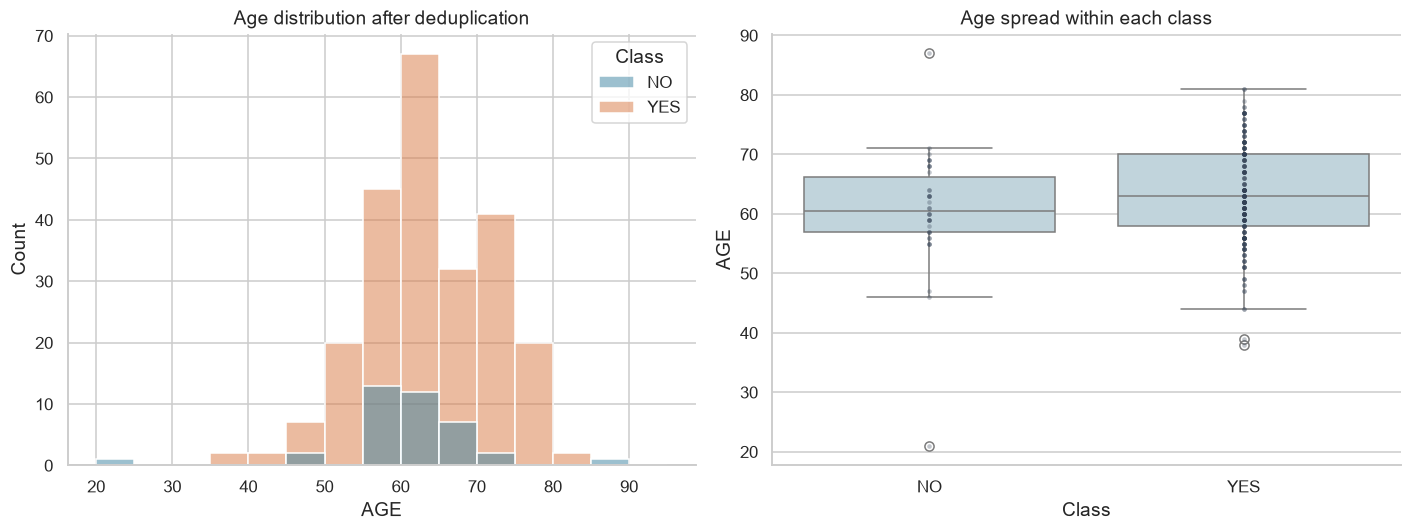

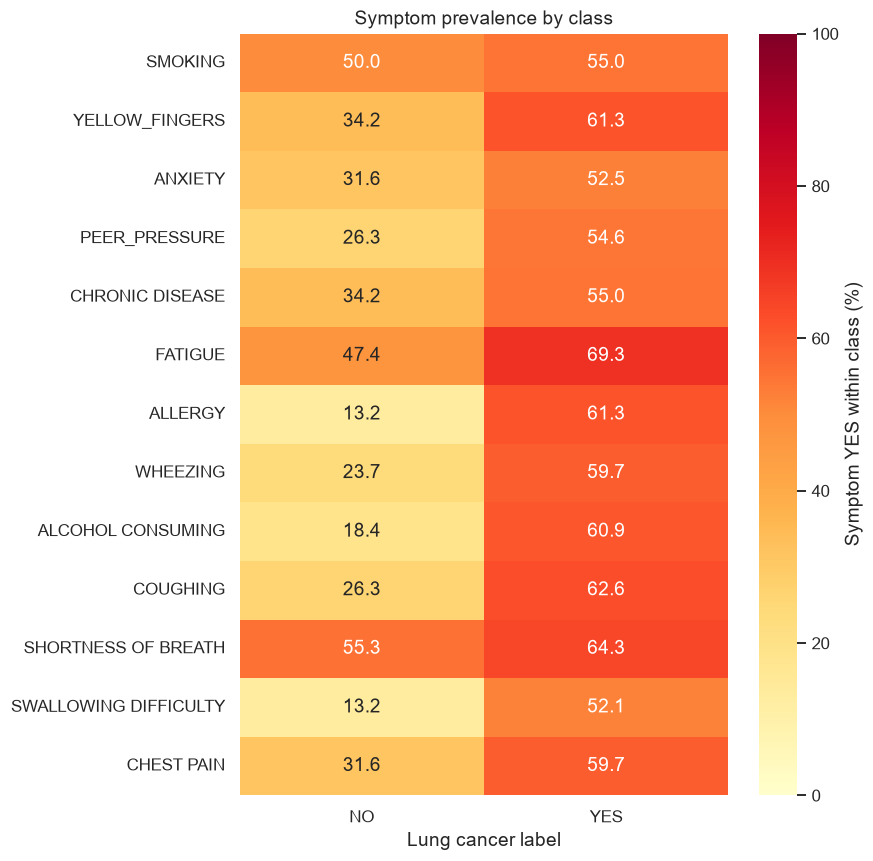

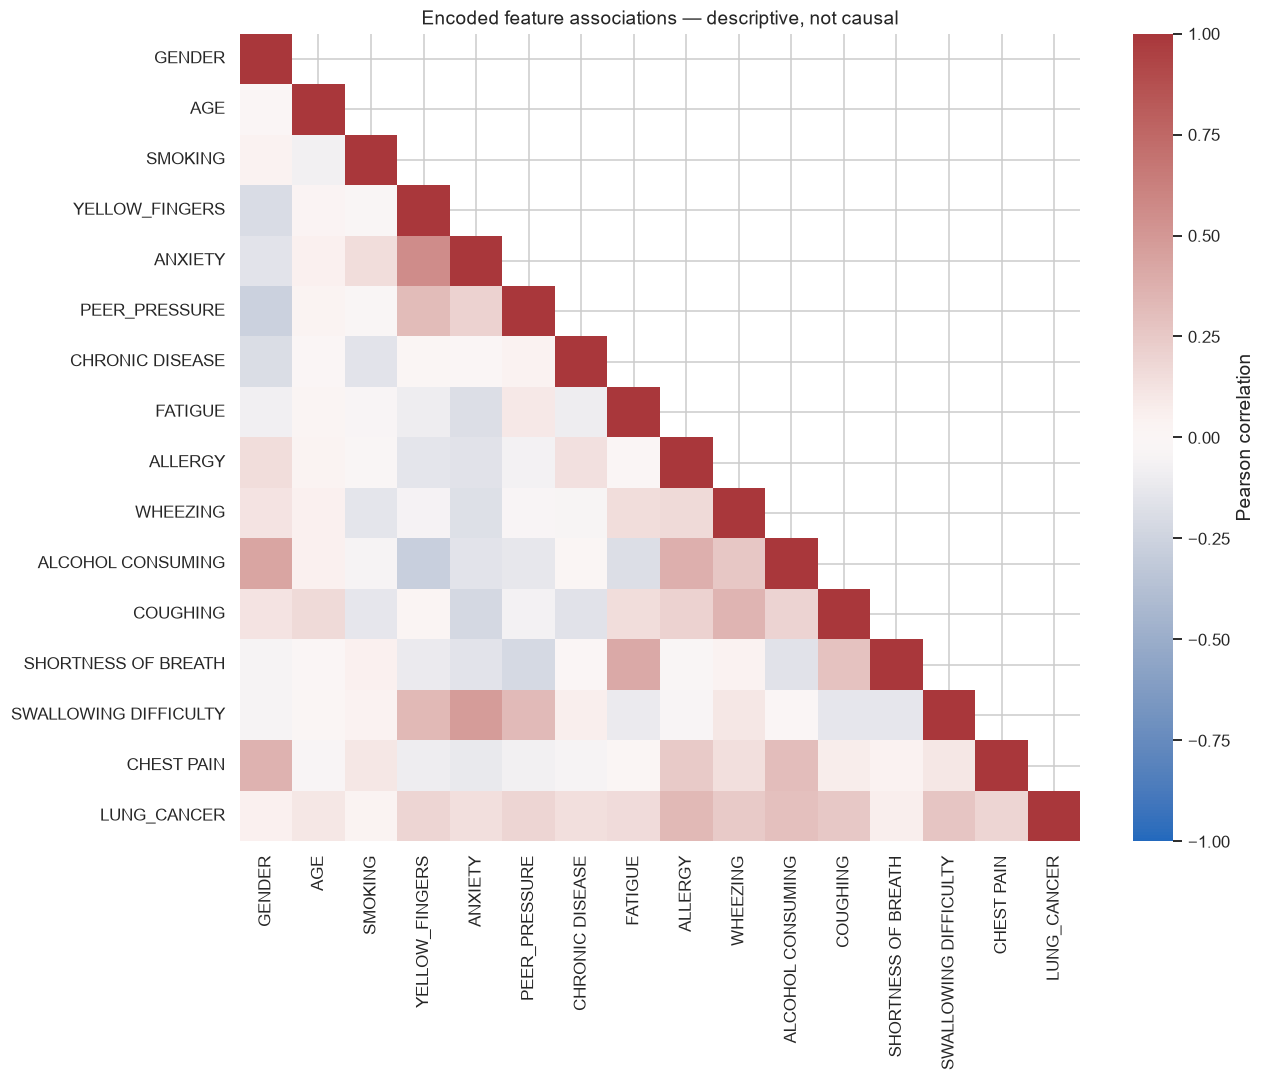

In [4]:
eda = encoded.copy()
eda['Class'] = eda[TARGET].map({0:'NO',1:'YES'})
fig, axes = plt.subplots(1,2,figsize=(13,5))
sns.histplot(data=eda, x='AGE', hue='Class', hue_order=LABELS, palette=COLORS,
             bins=np.arange(20,96,5), multiple='layer', ax=axes[0])
axes[0].set_title('Age distribution after deduplication')
sns.boxplot(data=eda, x='Class', y='AGE', order=LABELS, color='#BCD6E0', ax=axes[1])
sns.stripplot(data=eda, x='Class', y='AGE', order=LABELS, color='#334155', alpha=.3, size=3, jitter=False, ax=axes[1])
axes[1].set_title('Age spread within each class')
savefig(fig, '03_age_distribution')
rates = eda.groupby('Class')[symptoms].mean().reindex(LABELS).T * 100
fig, ax = plt.subplots(figsize=(8,8))
sns.heatmap(rates, annot=True, fmt='.1f', cmap='YlOrRd', vmin=0, vmax=100,
            cbar_kws={'label':'Symptom YES within class (%)'}, ax=ax)
ax.set(title='Symptom prevalence by class', xlabel='Lung cancer label', ylabel='')
savefig(fig, '04_symptom_prevalence')
fig, ax = plt.subplots(figsize=(12,10))
corr = encoded[features+[TARGET]].corr()
sns.heatmap(corr, mask=np.triu(np.ones_like(corr,dtype=bool), k=1), cmap='vlag',
            center=0, vmin=-1,vmax=1, ax=ax, cbar_kws={'label':'Pearson correlation'})
ax.set_title('Encoded feature associations — descriptive, not causal')
savefig(fig, '05_feature_correlations')


## 2. Load saved model results and verify their consistency
Random Forest predictions are read directly from its saved CSV. XGBoost JSON files are
loaded for inference only. Identical model files are grouped by SHA-256, so multiple selection
labels are not presented as independent trained models.

If XGBoost cannot be loaded, a confusion matrix is recovered **only if exactly one integer
matrix satisfies all saved accuracy/precision/recall/F1 values and test class counts**.
That fallback is labelled explicitly: it does not recover per-row predictions or ROC curves,
and assumes the saved summary refers to the current test set. Inference that disagrees with
saved metrics stops execution rather than silently mixing incompatible artifacts.


In [5]:
rf_saved = js(RF_DIR / 'holdout/test_metrics.json')
rf_report = js(RF_DIR / 'holdout/classification_report.json')
rf_meta = js(RF_DIR / 'training_metadata.json')
rf_pred = csv(RF_DIR / 'holdout/test_predictions.csv')
assert len(rf_pred) == len(test)
assert np.array_equal(rf_pred['row_id'].to_numpy(), np.arange(len(test)))
assert np.array_equal(rf_pred['y_true'].to_numpy(), y_test.to_numpy()), 'RF labels do not align with test.csv.'
assert rf_pred['y_pred'].isin([0,1]).all() and rf_pred['probability_yes'].between(0,1).all()
rf_cm = confusion_matrix(y_test, rf_pred['y_pred'], labels=[0,1])
rf_cm_saved = csv(RF_DIR / 'holdout/confusion_matrix.csv', index_col=0).to_numpy()
assert np.array_equal(rf_cm, rf_cm_saved)
rf_metrics = metrics_from_cm(rf_cm, roc_auc_score(y_test,rf_pred['probability_yes']))
for label,key in [('Accuracy','accuracy'),('Balanced accuracy','balanced_accuracy'),('F1 macro','f1_macro'),
                  ('ROC-AUC','roc_auc'),('Recall NO','recall_no'),('Recall YES','recall_yes')]:
    assert np.isclose(rf_metrics[label],rf_saved[key]), f'RF mismatch: {key}'
assert np.isclose(rf_metrics['F1 YES'], rf_report['YES']['f1-score'])
models = {'Random Forest': {'cm':rf_cm, 'metrics':rf_metrics, 'pred':rf_pred['y_pred'].to_numpy(),
                           'prob':rf_pred['probability_yes'].to_numpy(), 'source':'Saved per-row predictions'}}
xgb_summary = csv(xgb_result('xgb_final_test_results.csv'))
groups = {}
for selector in xgb_summary['Selected By']:
    path = ROOT / f'src/models/XGBoost/saved/best_xgb_{selector.lower()}_lung_cancer.json'
    if path.exists():
        digest = hashlib.sha256(source(path).read_bytes()).hexdigest()
    else:
        digest = f'missing:{selector}'  # Never infer model identity from equal aggregate scores.
    groups.setdefault(digest, {'path':path, 'selectors':[]})['selectors'].append(selector)

provenance = []
for group in groups.values():
    selectors, path = group['selectors'], group['path']
    rows = xgb_summary.set_index('Selected By').loc[selectors]
    assert np.allclose(rows.to_numpy(dtype=float), rows.iloc[0].to_numpy(dtype=float)), 'Identical JSONs have conflicting summaries.'
    row = rows.iloc[0]
    name = 'XGBoost [' + '/'.join(selectors) + ']'
    pred, prob = None, None
    model = None
    if xgb is not None and path.exists():
        try:
            model = xgb.XGBClassifier()
            model.load_model(path)
            pred = model.predict(X_test)
            prob = model.predict_proba(X_test)[:,list(model.classes_).index(1)]
        except Exception as exc:
            pred, prob = None, None
            note(f'{name}: inference unavailable ({type(exc).__name__}: {exc}); using aggregate-only fallback.')
    if pred is None:
        cm = unique_cm_from_summary(row, y_test)
        m = metrics_from_cm(cm,row['ROC-AUC'])
        origin = 'Recovered uniquely from aggregate CSV; current test support assumed'
        note(f'{name}: {origin}. ROC/PR curves and paired errors unavailable.')
    else:
        cm = confusion_matrix(y_test,pred,labels=[0,1])
        m = metrics_from_cm(cm,roc_auc_score(y_test,prob))
        origin = 'Inference from saved JSON; validated against saved CSV'
        for a,b in [('Accuracy','Accuracy'),('Precision YES','Precision'),('Recall YES','Recall'),
                    ('F1 YES','F1-Score'),('ROC-AUC','ROC-AUC')]:
            if not np.isclose(m[a],float(row[b]),atol=1e-7,rtol=0):
                raise ValueError(f'{name}: {a} differs from saved results; check model/test/result versions.')
    models[name] = {'cm':cm,'metrics':m,'pred':pred,'prob':prob,'source':origin}
    provenance.append({'Model':name,'JSON':str(path.relative_to(ROOT)), 'Source':origin})
table(pd.DataFrame(provenance), 'xgb_provenance')
metric_table = pd.DataFrame({name:item['metrics'] for name,item in models.items()}).T[METRICS]
table(metric_table.rename_axis('Model').reset_index(), 'holdout_metrics_aligned')


,Model,JSON,Source
0,XGBoost [AUC/Accuracy/Precision],src\models\XGBoost\saved\best_xgb_auc_lung_can...,Inference from saved JSON; validated against s...
1,XGBoost [Recall/F1],src\models\XGBoost\saved\best_xgb_recall_lung_...,Inference from saved JSON; validated against s...


,Model,Accuracy,Balanced accuracy,Precision YES,Recall YES,Recall NO,F1 YES,F1 macro,ROC-AUC
0,Random Forest,0.928571,0.958333,1.000000,0.916667,1.000,0.956522,0.878261,0.976562
1,XGBoost [AUC/Accuracy/Precision],0.928571,0.958333,1.000000,0.916667,1.000,0.956522,0.878261,0.966146
2,XGBoost [Recall/F1],0.946429,0.916667,0.978723,0.958333,0.875,0.968421,0.895975,0.971354


### Confusion matrices for each distinct saved model
Rows are actual labels; columns are predicted labels. The right-hand plot normalizes each
actual class separately. For binary YES classification: top-left TN, top-right FP,
bottom-left FN, bottom-right TP.


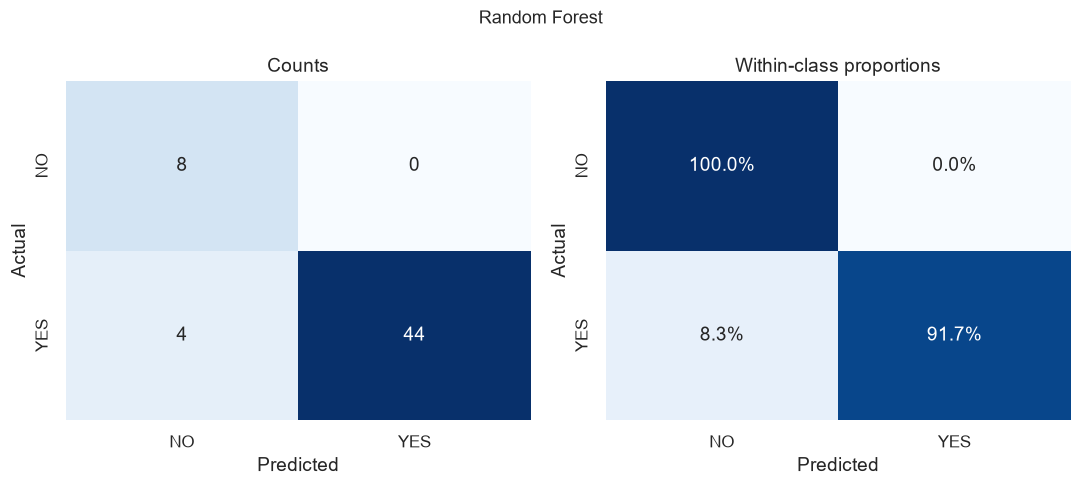

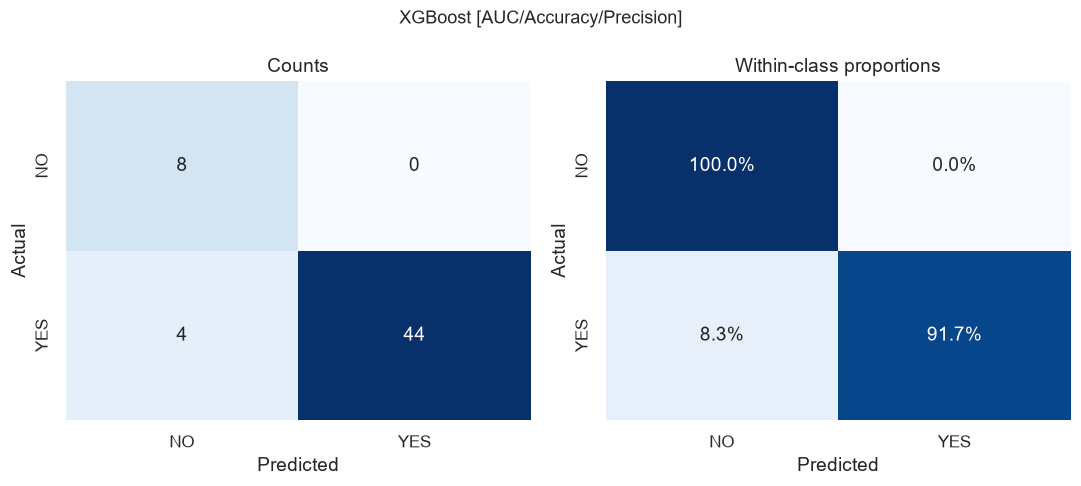

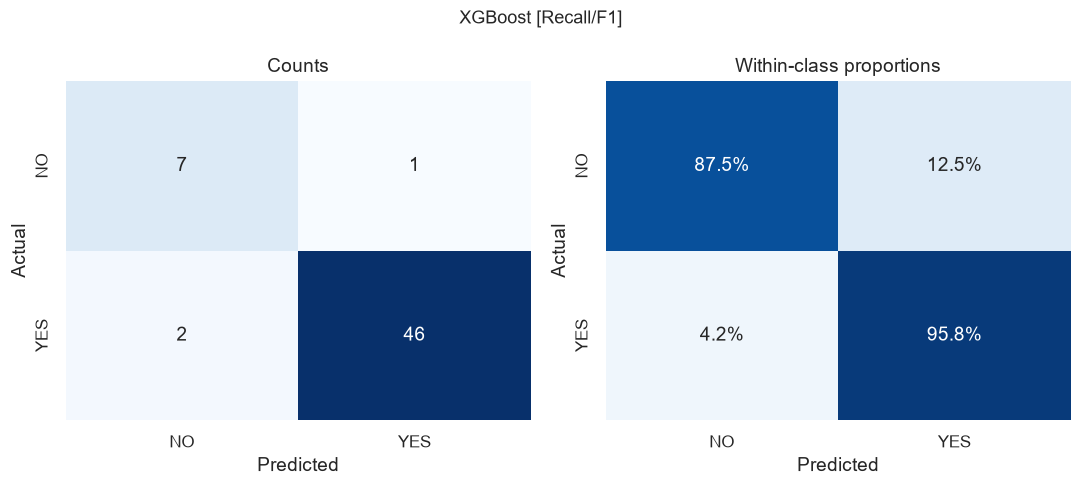

In [6]:
for i,(name,item) in enumerate(models.items(), start=1):
    cm = item['cm']
    normalized = np.divide(cm,cm.sum(axis=1,keepdims=True),out=np.zeros_like(cm,dtype=float),where=cm.sum(axis=1,keepdims=True)!=0)
    fig, axes = plt.subplots(1,2,figsize=(10,4.5))
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,xticklabels=LABELS,yticklabels=LABELS,ax=axes[0])
    sns.heatmap(normalized,annot=True,fmt='.1%',vmin=0,vmax=1,cmap='Blues',cbar=False,
                xticklabels=LABELS,yticklabels=LABELS,ax=axes[1])
    for ax,title in zip(axes,['Counts','Within-class proportions']):
        ax.set(xlabel='Predicted',ylabel='Actual',title=title)
    fig.suptitle(name + (' — aggregate reconstruction' if item['pred'] is None else ''),fontsize=12)
    savefig(fig,f'06_confusion_matrix_{i}')


## 3. Compare models using identical metric definitions
F1 YES is the positive-class F1. F1 macro averages NO and YES equally. They must not be
interchanged. Balanced accuracy averages the two class recalls. All measures below use the
same holdout set; the majority classifier is a reference, not a newly trained model.


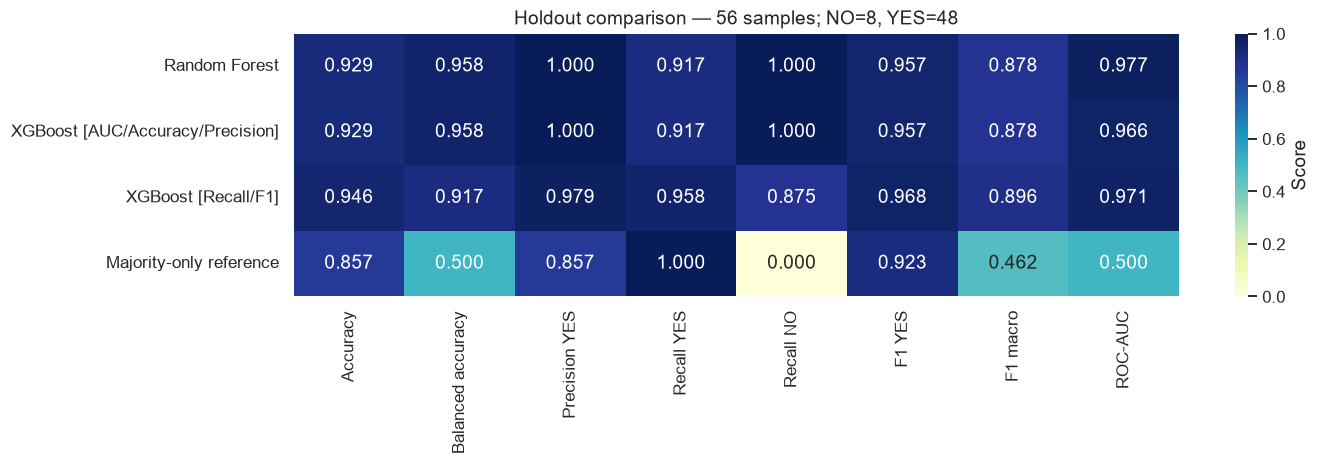

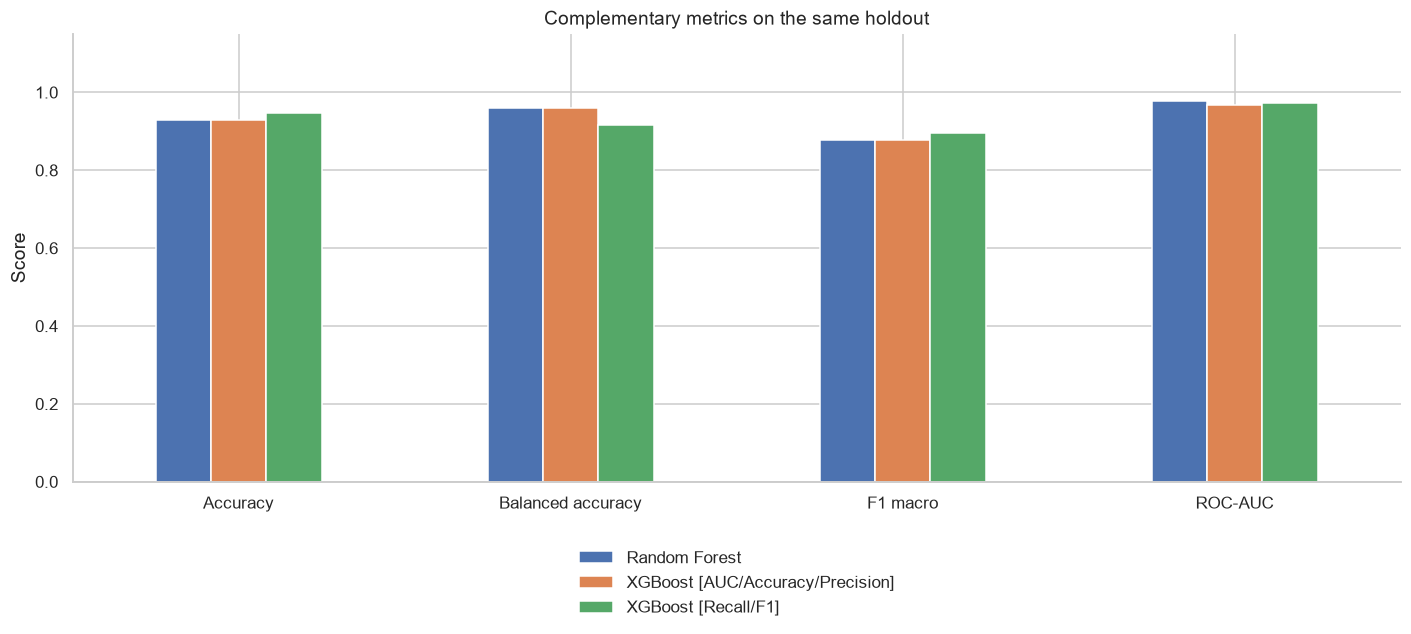

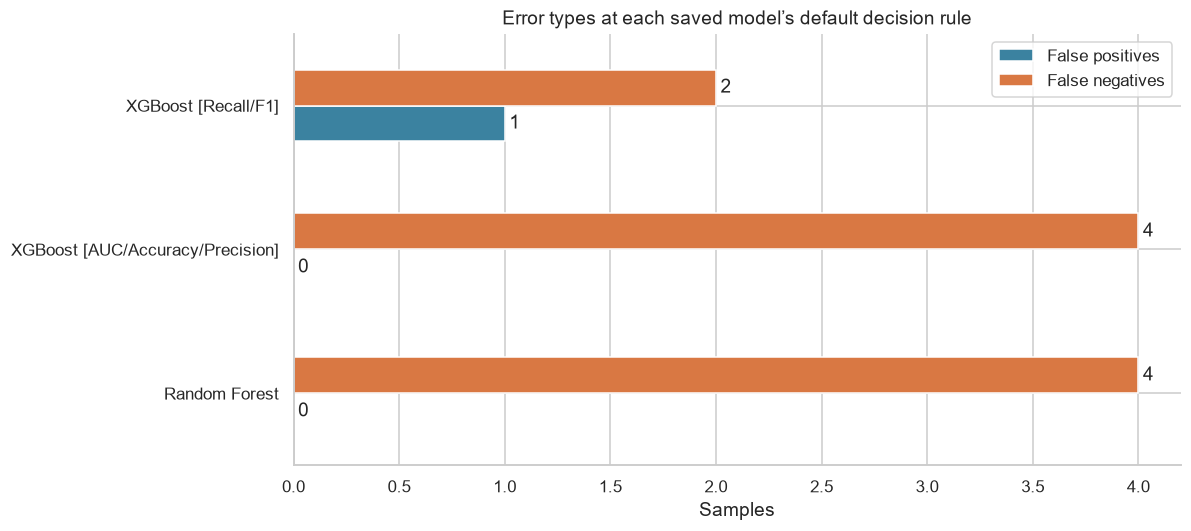

One changed prediction shifts test accuracy by 1.79%.
One NO sample shifts NO recall by 12.50%.


In [7]:
majority_label = int(train[TARGET].mode().iloc[0])
dummy_pred = np.full(len(y_test),majority_label)
dummy_cm = confusion_matrix(y_test,dummy_pred,labels=[0,1])
comparison = pd.concat([metric_table, pd.DataFrame([metrics_from_cm(dummy_cm,.5)],index=['Majority-only reference'])])
fig, ax = plt.subplots(figsize=(13, max(4,len(comparison)*1.1)))
sns.heatmap(comparison,annot=True,fmt='.3f',cmap='YlGnBu',vmin=0,vmax=1,ax=ax,cbar_kws={'label':'Score'})
ax.set(title=f'Holdout comparison — {len(test)} samples; NO={(y_test==0).sum()}, YES={(y_test==1).sum()}',xlabel='',ylabel='')
savefig(fig,'07_model_metric_comparison')
fig, ax = plt.subplots(figsize=(13,6))
metric_table[['Accuracy','Balanced accuracy','F1 macro','ROC-AUC']].T.plot.bar(ax=ax,rot=0)
ax.set(ylim=(0,1.15),ylabel='Score',xlabel='',title='Complementary metrics on the same holdout')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.12),ncol=1,frameon=False)
savefig(fig,'08_grouped_model_comparison')
errors = pd.DataFrame([{'Model':name,'False positives':int(item['cm'][0,1]),'False negatives':int(item['cm'][1,0])}
                       for name,item in models.items()]).set_index('Model')
fig, ax = plt.subplots(figsize=(11,5))
errors.plot.barh(ax=ax,color=['#3B82A0','#D97843'])
for container in ax.containers:
    ax.bar_label(container,padding=3)
ax.set(title='Error types at each saved model’s default decision rule',xlabel='Samples',ylabel='')
savefig(fig,'09_error_counts')
print(f'One changed prediction shifts test accuracy by {1/len(test):.2%}.')
print(f'One NO sample shifts NO recall by {1/(y_test==0).sum():.2%}.')


### ROC and precision–recall curves
Only real per-sample probability scores can produce these curves. Aggregate CSV scores
cannot reconstruct them. Average precision (AP) is calculated from predictions and is
distinct from the trapezoidal area under a precision–recall curve. The PR baseline equals
the positive-class prevalence, which is already high here.


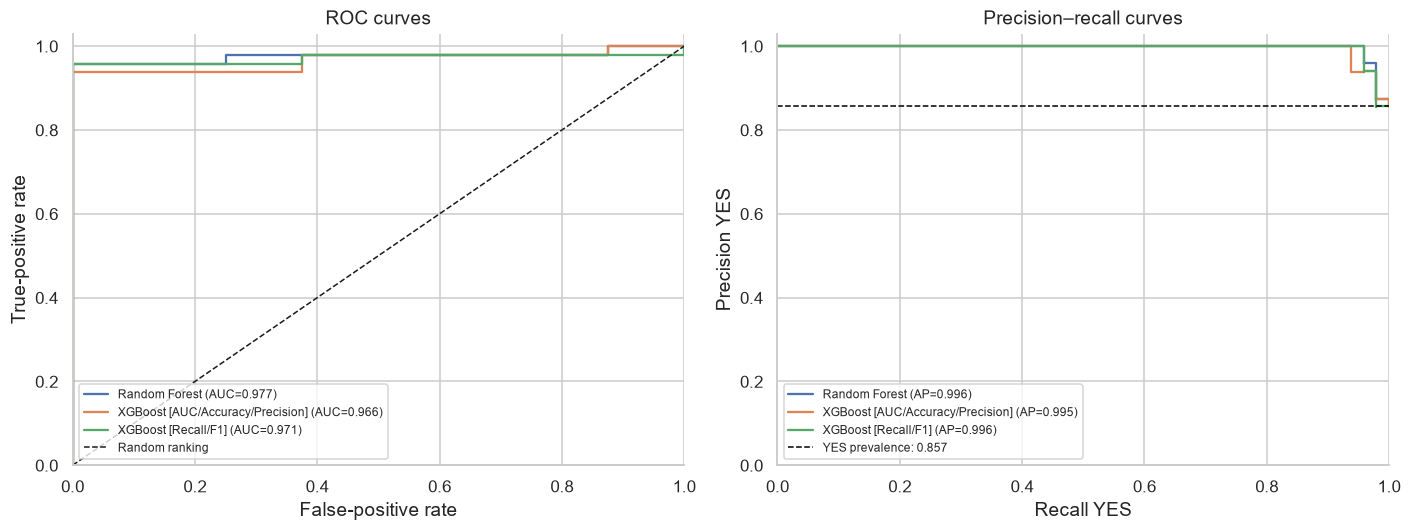

,Model,Average precision YES
0,Random Forest,0.996498
1,XGBoost [AUC/Accuracy/Precision],0.994823
2,XGBoost [Recall/F1],0.995774


In [8]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
ap_rows = []
for name,item in models.items():
    if item['prob'] is None:
        continue
    fpr,tpr,_ = roc_curve(y_test,item['prob'])
    precision,recall,_ = precision_recall_curve(y_test,item['prob'])
    ap = average_precision_score(y_test,item['prob'])
    axes[0].plot(fpr,tpr,label=f"{name} (AUC={item['metrics']['ROC-AUC']:.3f})")
    axes[1].step(recall,precision,where='post',label=f'{name} (AP={ap:.3f})')
    ap_rows.append({'Model':name,'Average precision YES':ap})
axes[0].plot([0,1],[0,1],'k--',lw=1,label='Random ranking')
axes[1].axhline(y_test.mean(),color='black',ls='--',lw=1,label=f'YES prevalence: {y_test.mean():.3f}')
axes[0].set(xlabel='False-positive rate',ylabel='True-positive rate',title='ROC curves',xlim=(0,1),ylim=(0,1.03))
axes[1].set(xlabel='Recall YES',ylabel='Precision YES',title='Precision–recall curves',xlim=(0,1),ylim=(0,1.03))
for ax in axes:
    ax.legend(loc='lower left',fontsize=8)
savefig(fig,'10_roc_precision_recall')
table(pd.DataFrame(ap_rows),'average_precision')


## 4. Additional criterion: validation stability and shared errors
Fold-level scores expose variability hidden by one holdout score. The tuned RF row below is
selected by its saved parameters, not by the test result. Its CV scores were used for tuning,
so they are selection estimates, not an independent nested-CV evaluation. XGBoost's fold
scores describe the fixed training configuration, not repeated evaluations of one saved model.
No error bar here is presented as a confidence interval.


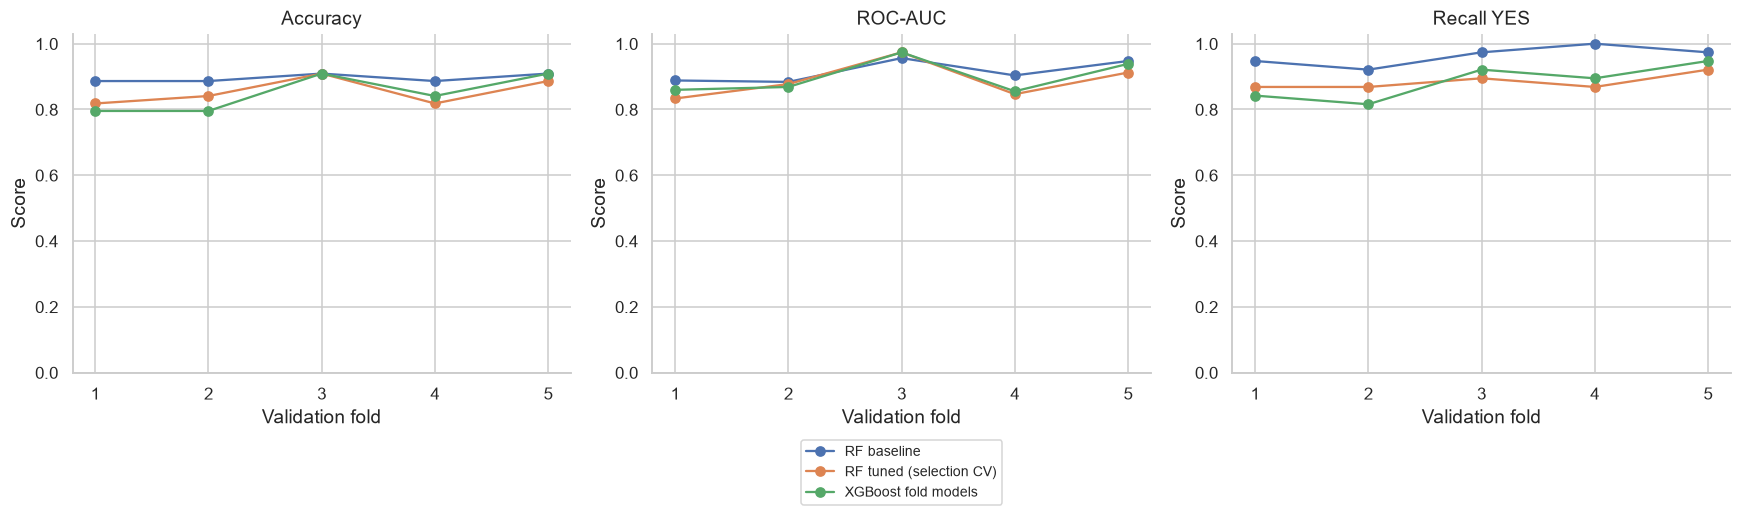

,Model,Metric,mean,std,min,max
0,RF baseline,Accuracy,0.895455,0.012448,0.886364,0.909091
1,RF baseline,ROC-AUC,0.915789,0.033782,0.883772,0.956140
2,RF baseline,Recall YES,0.963158,0.030005,0.921053,1.000000
3,RF tuned (selection CV),Accuracy,0.854545,0.041286,0.818182,0.909091
4,RF tuned (selection CV),ROC-AUC,0.888596,0.056475,0.833333,0.973684
5,RF tuned (selection CV),Recall YES,0.884211,0.023538,0.868421,0.921053
6,XGBoost fold models,Accuracy,0.850000,0.057045,0.795455,0.909091
7,XGBoost fold models,ROC-AUC,0.899123,0.053717,0.855263,0.973684
8,XGBoost fold models,Recall YES,0.884211,0.054570,0.815789,0.947368


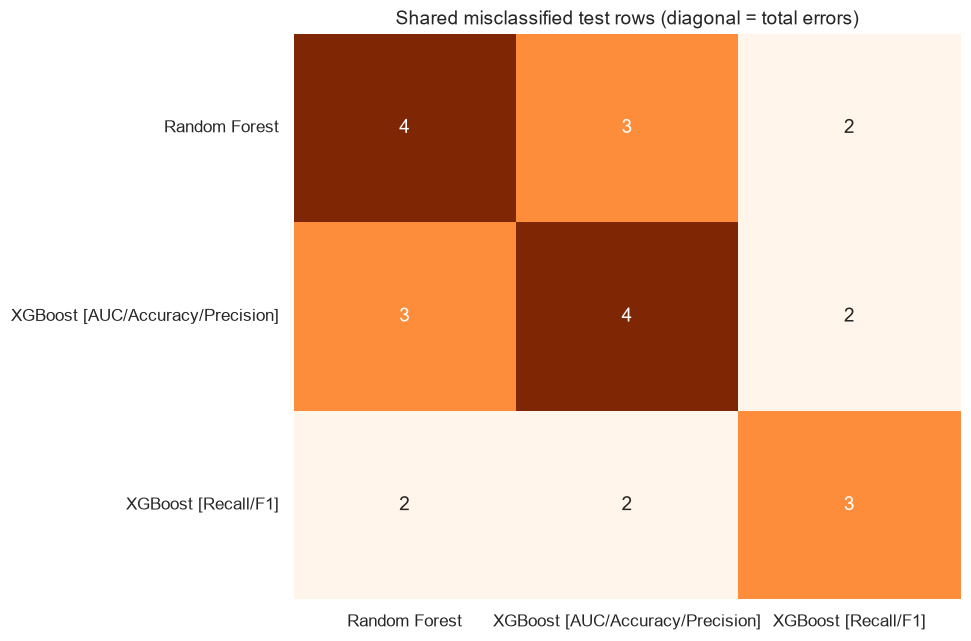

In [9]:
rf_cv = csv(RF_DIR / 'rf_baseline_cv.csv')
xgb_cv = csv(xgb_result('xgb_kfold_results.csv'))
search = csv(RF_DIR / 'search_results.csv')
selected_row = None
if rf_meta['selected_model'] == 'tuned_random_forest':
    for _,row in search.iterrows():
        # Match explicit parameter columns, without eval() on serialized dictionaries.
        ok = True
        for key in ['max_depth','min_samples_leaf','class_weight']:
            actual,expected = row['param_'+key],rf_meta['selected_params'][key]
            if expected is None:
                ok = ok and (pd.isna(actual) or str(actual) in ['None','nan'])
            elif isinstance(expected,(int,float)):
                ok = ok and pd.notna(actual) and float(actual) == expected
            else:
                ok = ok and str(actual) == str(expected)
        if ok:
            selected_row = row
            break
    if selected_row is None:
        raise ValueError('Saved RF parameters do not match search_results.csv.')
cv_rows = []
for title,rf_key,xgb_key in [('Accuracy','accuracy','Accuracy'),('ROC-AUC','roc_auc','ROC-AUC'),('Recall YES','recall_yes','Recall')]:
    for i,value in enumerate(rf_cv['test_'+rf_key],start=1):
        cv_rows.append({'Model':'RF baseline','Metric':title,'Fold':i,'Score':value})
    if selected_row is not None:
        for i in range(int(rf_meta['n_splits'])):
            cv_rows.append({'Model':'RF tuned (selection CV)','Metric':title,'Fold':i+1,'Score':float(selected_row[f'split{i}_test_{rf_key}'])})
    for _,row in xgb_cv.iterrows():
        cv_rows.append({'Model':'XGBoost fold models','Metric':title,'Fold':int(row['Fold']),'Score':row[xgb_key]})
cv_long = pd.DataFrame(cv_rows)
fig,axes = plt.subplots(1,3,figsize=(16,5))
for ax,title in zip(axes,['Accuracy','ROC-AUC','Recall YES']):
    subset = cv_long[cv_long['Metric']==title]
    for name,group in subset.groupby('Model',sort=False):
        ax.plot(group['Fold'],group['Score'],marker='o',label=name)
    ax.set(title=title,xlabel='Validation fold',ylabel='Score',ylim=(0,1.03),xticks=sorted(subset['Fold'].unique()))
axes[1].legend(loc='upper center',bbox_to_anchor=(.5,-.18),fontsize=9)
savefig(fig,'11_cv_stability')
cv_stats = cv_long.groupby(['Model','Metric'])['Score'].agg(['mean','std','min','max']).reset_index()
table(cv_stats,'cv_summary')

paired = {name:np.asarray(item['pred']) != y_test.to_numpy() for name,item in models.items() if item['pred'] is not None}
if len(paired) > 1:
    shared = pd.DataFrame({a:{b:int(np.sum(paired[a]&paired[b])) for b in paired} for a in paired})
    fig,ax = plt.subplots(figsize=(9,6))
    sns.heatmap(shared,annot=True,fmt='d',cmap='Oranges',cbar=False,ax=ax)
    ax.set_title('Shared misclassified test rows (diagonal = total errors)')
    savefig(fig,'12_shared_errors')
    per_row = test.copy()
    per_row.insert(0,'test_row_id',np.arange(len(test)))
    for name,item in models.items():
        if item['pred'] is not None:
            per_row[name+' prediction'] = item['pred']
            per_row[name+' probability YES'] = item['prob']
    per_row.to_csv(OUT/'aligned_test_predictions.csv',index=False)


## Conclusions and reproducibility
- Base cleansing decisions on the audit: remove exact duplicate records only with a documented
  rationale; do not delete plausible ages simply because a box plot flags them.
- Report class counts, balanced accuracy, both class recalls and macro F1 alongside accuracy.
- Compare saved XGBoost variants transparently; equal-file variants are aliases, not replications.
- With this small holdout, a one-sample change matters. CV variability complements the holdout;
  it does not establish statistical significance or clinical validity.
- Feature importance/SHAP and threshold optimization are intentionally outside this notebook's
  core comparisons. Neither should be inferred from a correlation heatmap. Threshold selection
  would require training/validation predictions, not optimization on the final test set.

The manifest records source hashes, package versions, notes, and figure names. It helps detect
stale results when source artifacts change. Original training and result files are never overwritten.


In [10]:
versions = {}
for package in ['numpy','pandas','matplotlib','seaborn','scikit-learn','xgboost']:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = 'not installed'
manifest = {'source_sha256':SOURCES,'package_versions':versions,'figures':FIGURES,'notes':NOTES,
            'test_samples':len(test),'class_counts':{label:int((y_test==i).sum()) for i,label in enumerate(LABELS)},
            'no_retraining':True}
(OUT/'visualization_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print(f'Saved {len(FIGURES)} figures in both PNG and SVG formats to {OUT}')
print('Saved aligned metrics, audit tables, CV summaries and source manifest.')


Saved 14 figures in both PNG and SVG formats to F:\Bach_khoa\HKCQ\HK261\Machine Learning\BTL\results\vis_res
Saved aligned metrics, audit tables, CV summaries and source manifest.
